# 01 — EDA: C-MAPSS turbofan degradation
Load raw data, validate 26 columns, engine lifetimes, sensor trajectories vs RUL, correlation, monotonicity, class balance, smoothing, operating-condition clusters.

In [1]:
import sys; sys.path.insert(0,'..')
import pandas as pd,numpy as np,matplotlib.pyplot as plt,seaborn as sns
from pathlib import Path
from src.data import *
from src.plots import setup; setup()
print('imports ok')

imports ok


In [2]:
for fd in ['FD001','FD002','FD003','FD004']:
    tr,te,rul=load_split('../data/raw' if Path('../data/raw').exists() else 'data/raw',fd)
    tr=add_class_labels(add_rul_train(tr))
    print(fd, tr.shape, 'units:', tr.unit.nunique(), '| life mean/max:', round(tr.groupby("unit").cycle.max().mean(),1), int(tr.groupby("unit").cycle.max().max()))
    print(' class dist:', tr.cls3.value_counts().to_dict())

FD001 (20631, 30) units: 100 | life mean/max: 206.3 362
 class dist: {'safe': 15531, 'warning': 3100, 'critical': 2000}
FD002 (53759, 30) units: 260 | life mean/max: 206.8 378
 class dist: {'safe': 40499, 'warning': 8060, 'critical': 5200}
FD003 (24720, 30) units: 100 | life mean/max: 247.2 525
 class dist: {'safe': 19620, 'warning': 3100, 'critical': 2000}


FD004 (61249, 30) units: 249 | life mean/max: 246.0 543
 class dist: {'safe': 48550, 'warning': 7719, 'critical': 4980}


../figures/FD001_ablation_cap.png


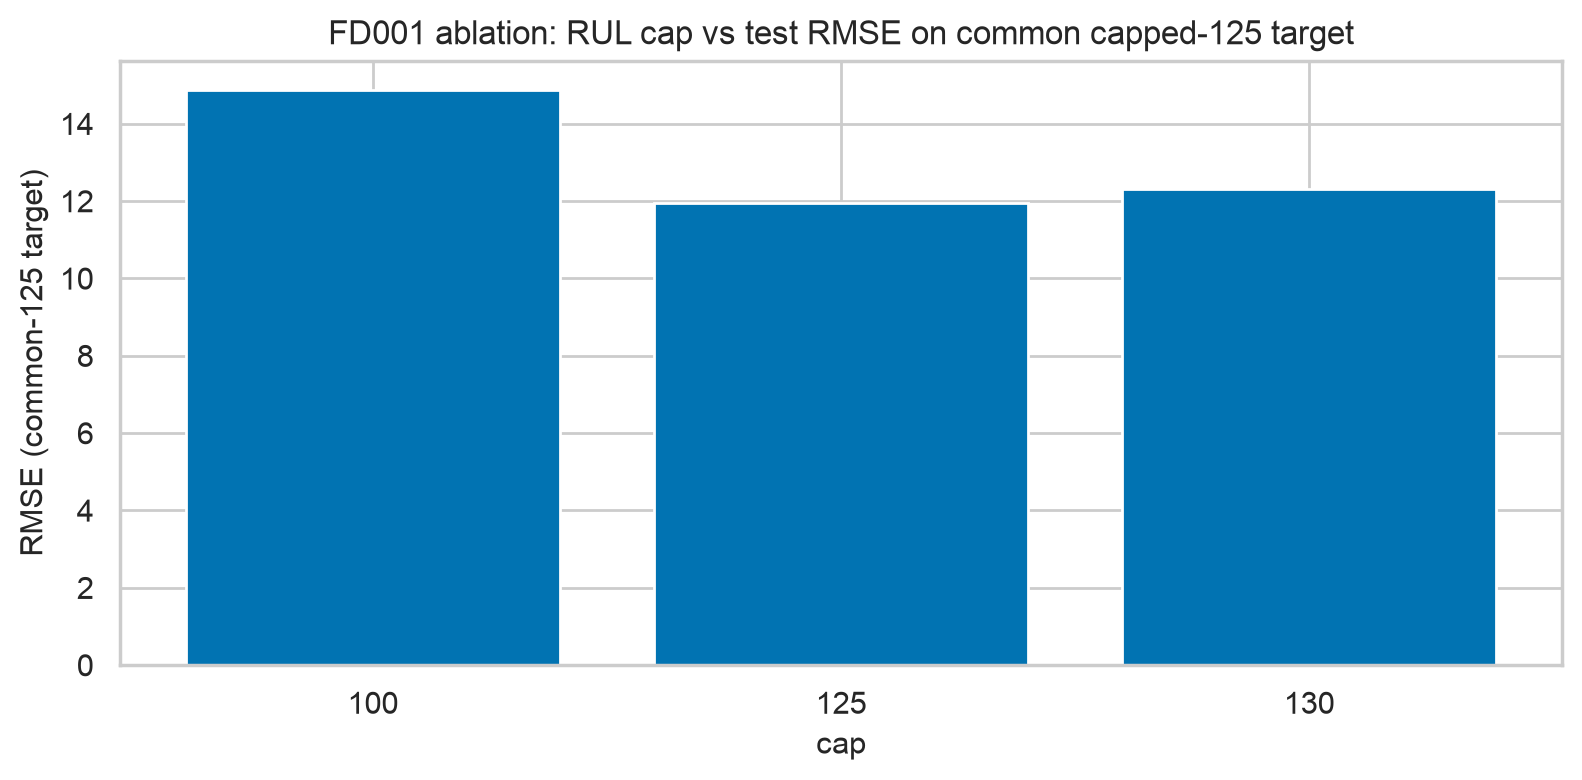

../figures/FD001_ablation_classweight.png


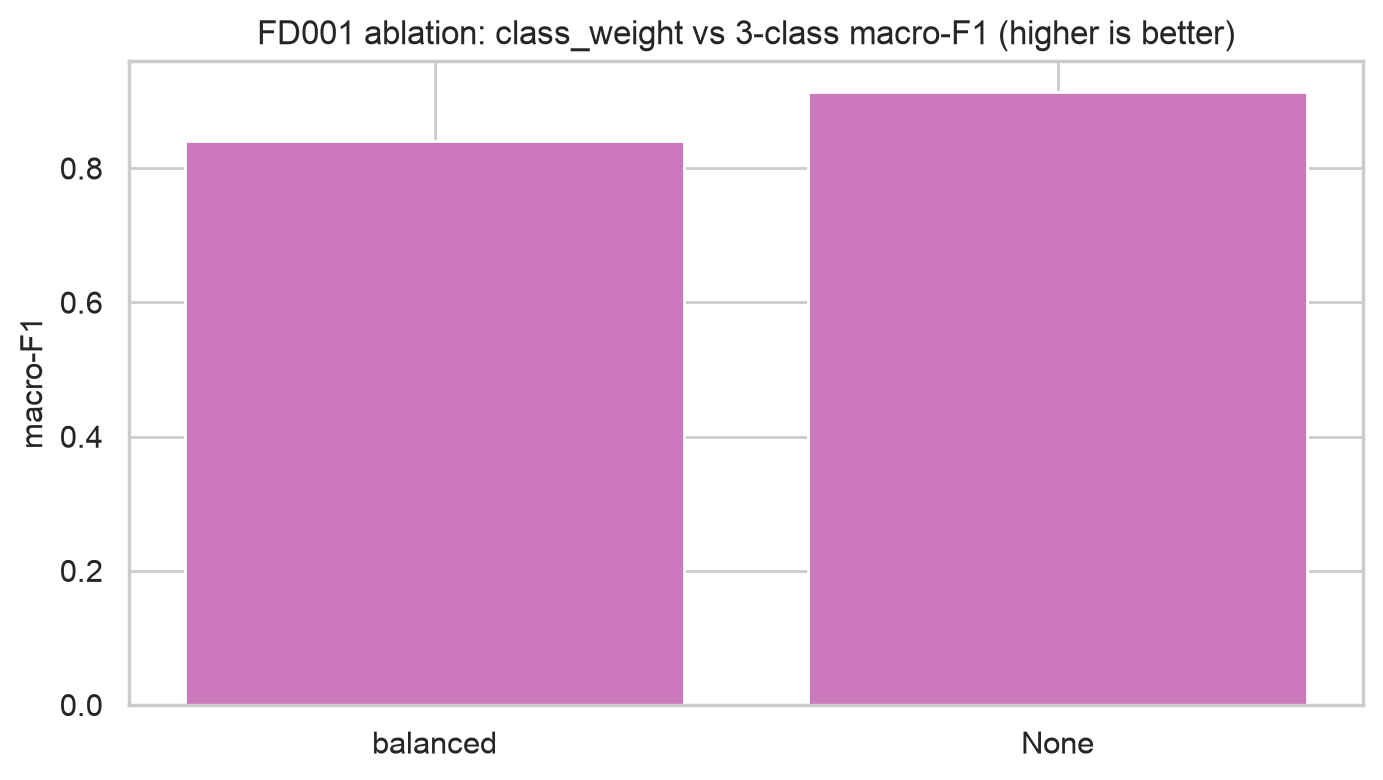

../figures/FD001_ablation_rolling.png


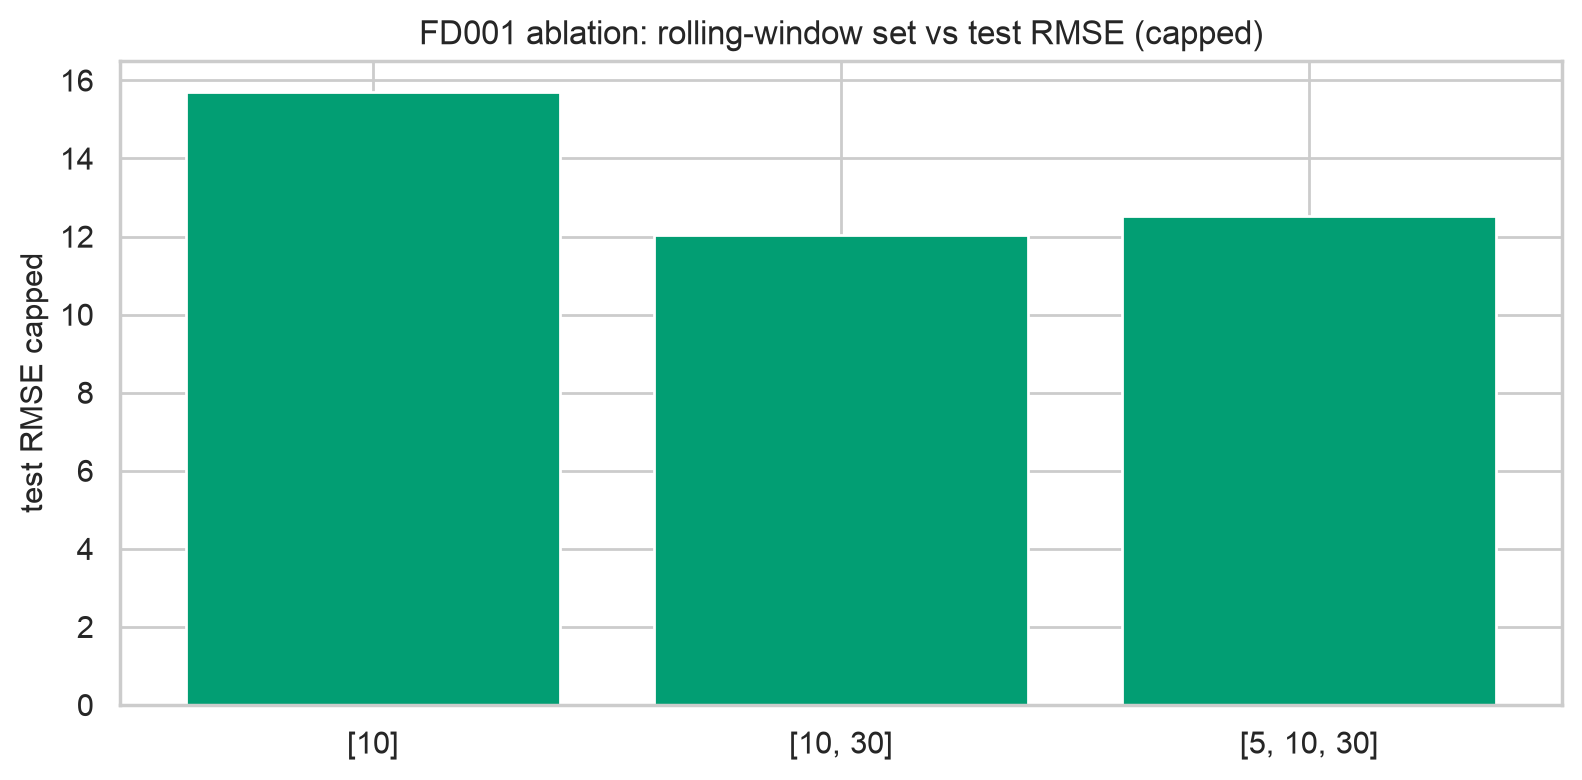

../figures/FD001_classdist.png


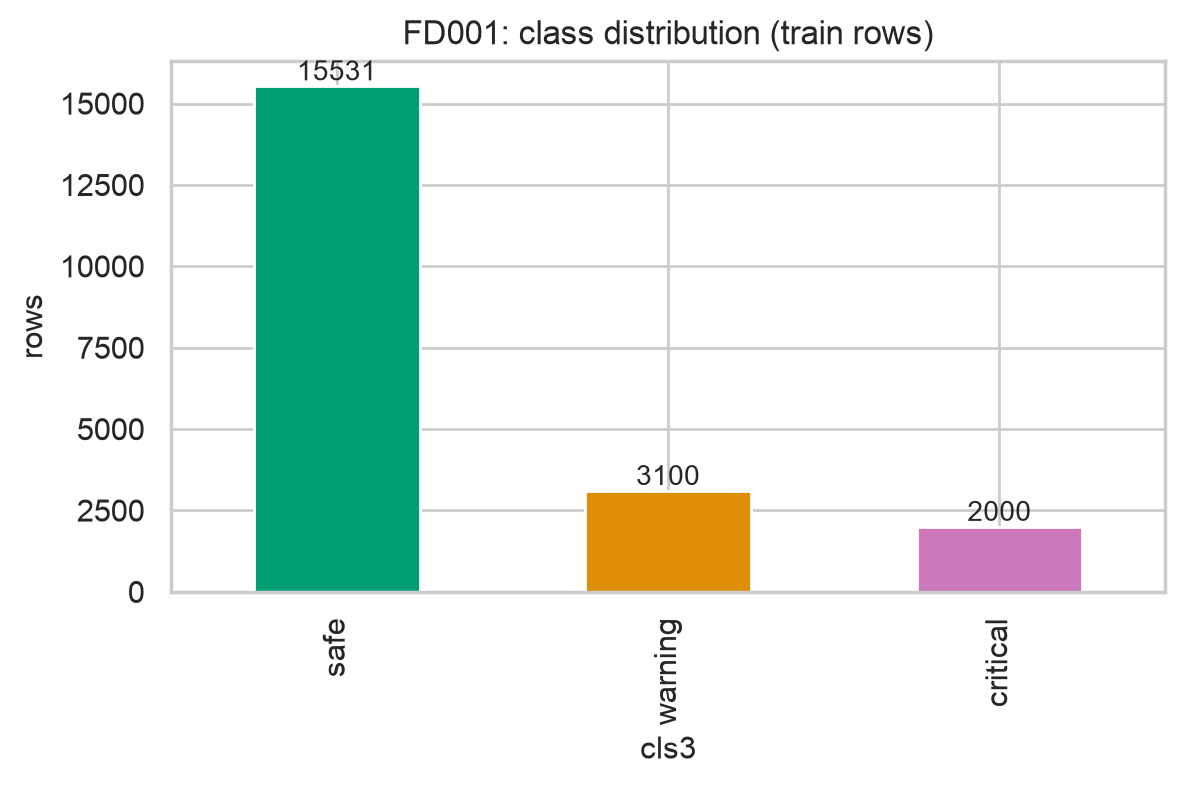

../figures/FD001_cm_3class_hgb.png


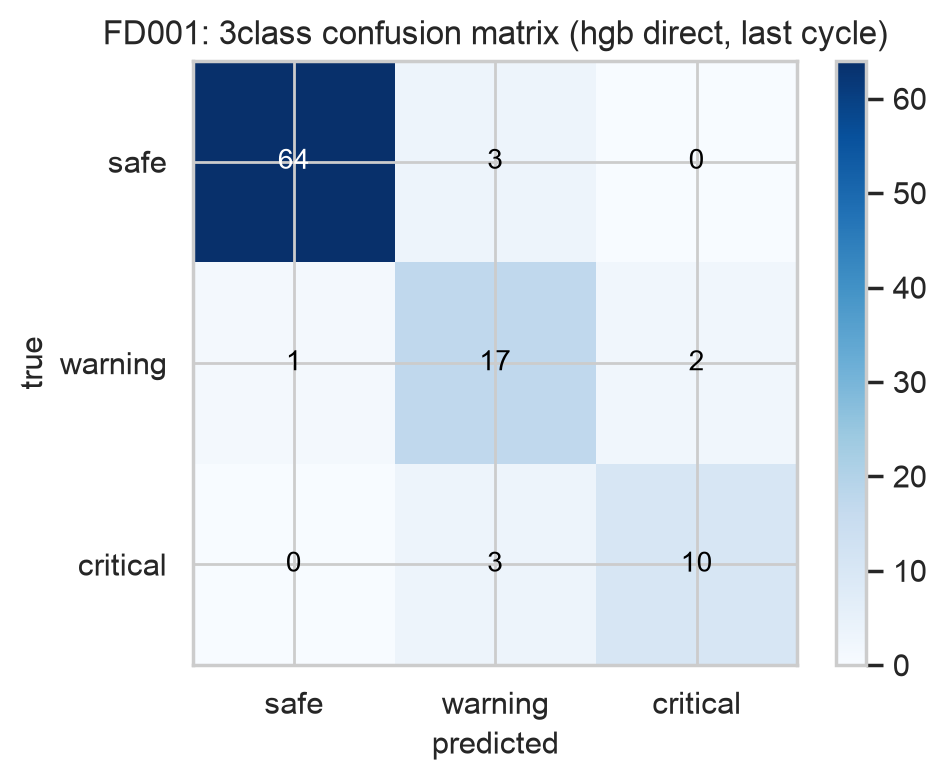

../figures/FD001_cm_3class_hgb_norm.png


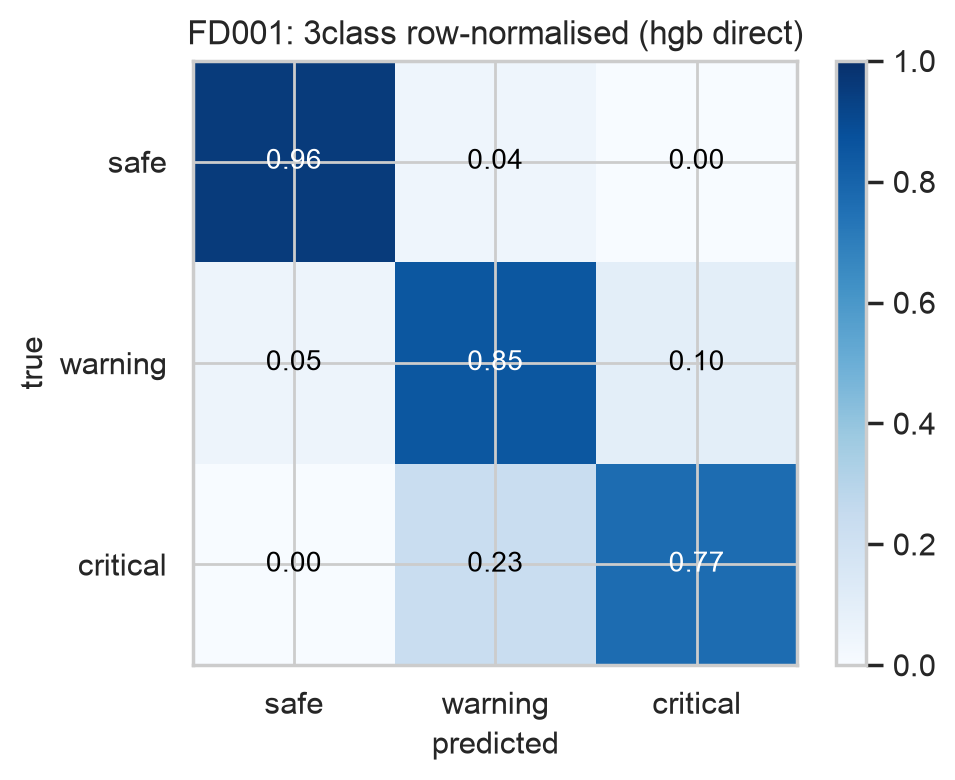

In [3]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob('../figures/FD001_*.png') or glob.glob('figures/FD001_*.png'))[:6]:
    print(f)
    display(Image(filename=f,width=700))